# Лабораторная работа № 5
## Нелинейные ИНС в задачах регрессии
### Вариант 10

**Дисциплина:** Основы машинного обучения  
**Выполнил(а):** ____________________  
**Группа:** ____________________  
**Проверил(а):** ____________________  
**Год:** 2026

Ноутбук предназначен для Google Colab. Для повторного расчёта выберите **Среда выполнения → Выполнить все**. GPU не требуется. Все таблицы и графики уже сохранены в выводах ячеек. Перед сдачей заполните данные титульного листа.

## 1. Цель работы
Построить и обучить нелинейную многослойную нейронную сеть для прогнозирования временного ряда, изучить влияние шага обучения и оценить качество одношагового восстановления обучающей выборки и многошагового прогноза.

## 2. Задание и исходные параметры
По строке 10 таблицы задания:

| Вариант | a | b | c | d | Входы | Нейроны скрытого слоя |
|:--:|:--:|:--:|:--:|:--:|:--:|:--:|
| 10 | 0,2 | 0,4 | 0,09 | 0,4 | 6 | 2 |

$$y(x)=0.2\cos(0.4x)+0.09\sin(0.4x).$$

Сеть **6–2–1**, один скрытый слой, скрытая активация — сигмоида, выходная — линейная. Шесть входов — последовательные прошлые значения ряда, выход — следующее значение; аргумент $x$ не подаётся в сеть.

**Принятые параметры эксперимента.** В методичке не заданы сетка, объём выборок, число эпох и набор значений $\alpha$, поэтому выбраны: $\Delta x=0.5$, 201 точка на $[0;100]$, обучение — первые 121 значение ($x=0\ldots60$), валидация — следующие 40 ($60.5\ldots80$), тест — последние 40 ($80.5\ldots100$). Обучение даёт 115 окон. Все модели обучаются 20 000 эпох с одинаковыми начальными весами, seed=10. Проверяются $\alpha\in\{0.01,0.03,0.1,0.3,0.5\}$.

Лучший $\alpha$ выбирается по минимальной MSE **рекурсивного прогноза на валидации**. Тест при выборе не используется. В формулировке методички $\alpha$ не определена; здесь это шаг градиентного спуска. Диапазон $\alpha$ конечный: глобальная оптимальность не утверждается.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from pathlib import Path

plt.rcParams.update({"figure.figsize": (11, 4), "font.size": 11, "axes.grid": True})
pd.set_option("display.max_rows", 150)
pd.set_option("display.float_format", lambda v: f"{v:.8f}")
OUT = Path("lab5_results")
OUT.mkdir(exist_ok=True)

## 3. Формирование выборок и устройство сети
Пусть $z_k=(y_k-\mu)/s$, где $\mu,s$ вычислены **только по обучающей части**. Обучающий пример:
$$\mathbf u_k=(z_{k-6},\ldots,z_{k-1}),\quad t_k=z_k.$$

Прямой проход:
$$\mathbf h=\sigma(\mathbf uW_1+\mathbf b_1),\quad \hat z=\mathbf hW_2+b_2,\quad \sigma(v)=\frac1{1+e^{-v}}.$$
Размеры: $W_1:6\times2$, $b_1:1\times2$, $W_2:2\times1$, $b_2:1\times1$. Всего **17 обучаемых параметров**.

Минимизируем средний квадрат ошибки в нормированной шкале:
$$L=\frac1N\sum_k(\hat z_k-t_k)^2,\qquad \theta\leftarrow\theta-\alpha\nabla_\theta L.$$
Градиенты вычисляются обратным распространением ошибки; обновления выполняются по всей обучающей выборке. Множитель $\sigma'(v)=\sigma(v)(1-\sigma(v))$ учитывается явно. На графиках ошибка возвращена в исходную шкалу: $\mathrm{MSE}_y=s^2L$.

In [2]:
import numpy as np

SEED = 10
LAGS = 6
EPOCHS = 20000
ALPHAS = [0.01, 0.03, 0.1, 0.3, 0.5]
DX = 0.5
x = np.arange(201) * DX
y = 0.2*np.cos(0.4*x) + 0.09*np.sin(0.4*x)
N_TRAIN, N_VAL = 121, 40
mu, scale = y[:N_TRAIN].mean(), y[:N_TRAIN].std()
z = (y-mu)/scale
X = np.array([z[k-LAGS:k] for k in range(LAGS, N_TRAIN)])
t = z[LAGS:N_TRAIN, None]

def sigmoid(v):
    return 1/(1+np.exp(-np.clip(v, -60, 60)))

def initial_weights():
    rng = np.random.default_rng(SEED)
    return [rng.normal(0, 0.3, (6, 2)), np.zeros((1, 2)),
            rng.normal(0, 0.3, (2, 1)), np.zeros((1, 1))]

def predict(X, weights):
    W1, b1, W2, b2 = weights
    return sigmoid(X@W1+b1)@W2+b2

def fit(alpha):
    weights = initial_weights()
    history = []
    for epoch in range(EPOCHS):
        W1, b1, W2, b2 = weights
        h = sigmoid(X@W1+b1)
        error = h@W2+b2-t
        history.append(float(np.mean(error**2)*scale**2))
        grad_out = 2*error/len(X)
        grad_hidden = (grad_out@W2.T)*h*(1-h)
        gradients = [X.T@grad_hidden, grad_hidden.sum(axis=0,keepdims=True),
                     h.T@grad_out, grad_out.sum(axis=0,keepdims=True)]
        weights = [w-alpha*g for w,g in zip(weights, gradients)]
    history.append(float(np.mean((predict(X,weights)-t)**2)*scale**2))
    return weights, np.array(history)

def recursive(seed, horizon, weights):
    window = list(seed)
    values = []
    for _ in range(horizon):
        p = float(predict(np.array(window[-LAGS:])[None,:],weights)[0,0])
        values.append(p)
        window.append(p)
    return np.array(values)*scale+mu

def metrics(true, predicted):
    e = np.asarray(predicted)-np.asarray(true)
    return dict(MSE=float(np.mean(e**2)), RMSE=float(np.sqrt(np.mean(e**2))),
                MAE=float(np.mean(np.abs(e))), MaxAE=float(np.max(np.abs(e))))

,Участок,Число,Начало x,Конец x
0,Обучение (исходный ряд),121,0.00000000,60.00000000
1,Обучающие пары,115,3.00000000,60.00000000
2,Валидация,40,60.50000000,80.00000000
3,Тест,40,80.50000000,100.00000000


Нормирование: μ=-0.00448459, s=0.15604003


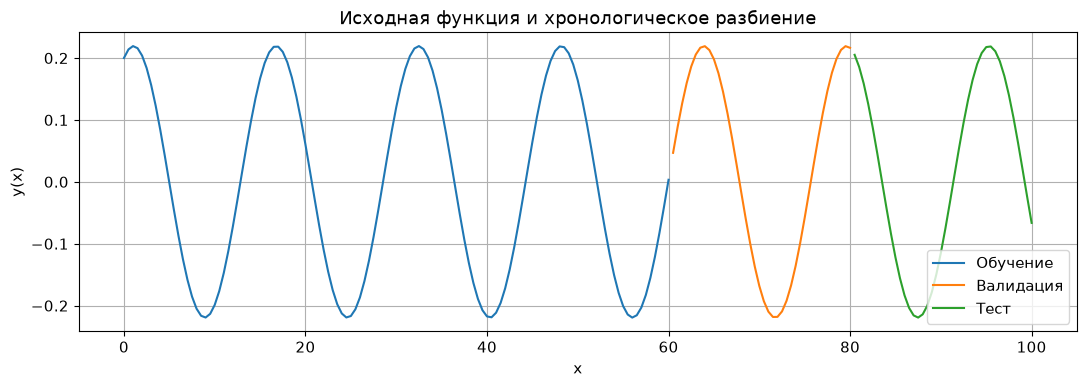

In [3]:
split_table = pd.DataFrame({
    "Участок": ["Обучение (исходный ряд)", "Обучающие пары", "Валидация", "Тест"],
    "Число": [121, len(X), 40, 40],
    "Начало x": [x[0], x[LAGS], x[N_TRAIN], x[N_TRAIN+N_VAL]],
    "Конец x": [x[N_TRAIN-1], x[N_TRAIN-1], x[N_TRAIN+N_VAL-1], x[-1]],
})
display(split_table)
print(f"Нормирование: μ={mu:.8f}, s={scale:.8f}")
fig, ax = plt.subplots()
ax.plot(x[:N_TRAIN],y[:N_TRAIN], label="Обучение")
ax.plot(x[N_TRAIN:N_TRAIN+N_VAL],y[N_TRAIN:N_TRAIN+N_VAL],label="Валидация")
ax.plot(x[N_TRAIN+N_VAL:],y[N_TRAIN+N_VAL:],label="Тест")
ax.set(xlabel="x",ylabel="y(x)",title="Исходная функция и хронологическое разбиение")
ax.legend(); fig.tight_layout(); fig.savefig(OUT/"01_data.png",dpi=160); plt.show()

## 4. Подбор шага обучения
Каждая модель начинает обучение с одинаковых весов. Для прогноза на валидации ей доступны только последние шесть истинных значений обучения; далее на вход подаются её собственные прогнозы. Учитывается ошибка всех 40 шагов. Выбирается финальное состояние модели после 20 000 эпох, без переобучения на тесте или валидации.

,α,MSE обучения,MSE валидации (40 шагов),RMSE валидации
0,0.01000000,0.00004574,0.00031444,0.01773258
1,0.03000000,0.00000053,0.00000322,0.00179456
2,0.10000000,0.00000033,0.00000055,0.00074123
3,0.30000000,0.00000017,0.00000028,0.00053325
4,0.50000000,0.00000351,0.00016613,0.01288922


Выбран α = 0.3: минимальная MSE валидации среди проверенных значений.


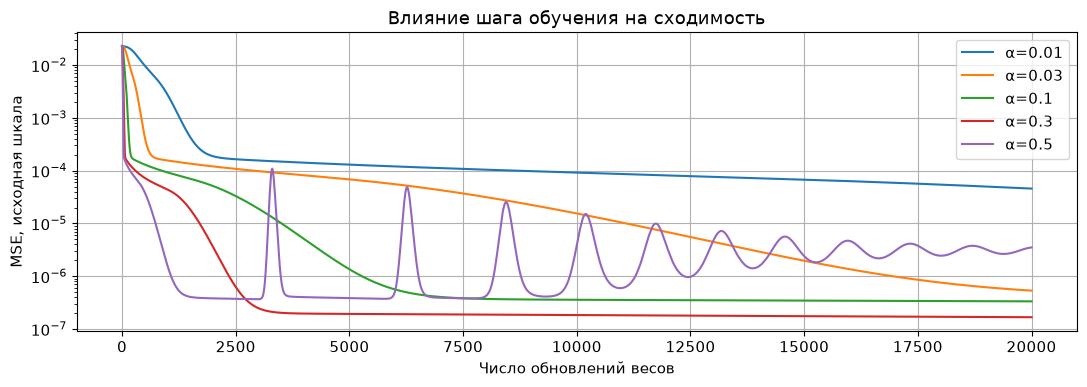

In [4]:
runs = {}
rows = []
for alpha in ALPHAS:
    weights, history = fit(alpha)
    val_pred = recursive(z[N_TRAIN-LAGS:N_TRAIN], N_VAL, weights)
    val_metrics = metrics(y[N_TRAIN:N_TRAIN+N_VAL], val_pred)
    assert np.isfinite(history).all() and np.isfinite(val_pred).all()
    runs[alpha] = dict(weights=weights, history=history, validation=val_pred)
    rows.append({"α": alpha, "MSE обучения": history[-1],
                 "MSE валидации (40 шагов)": val_metrics["MSE"],
                 "RMSE валидации": val_metrics["RMSE"]})
alpha_table = pd.DataFrame(rows)
best_alpha = float(alpha_table.loc[alpha_table["MSE валидации (40 шагов)"].idxmin(),"α"])
best = runs[best_alpha]
weights, history = best["weights"], best["history"]
display(alpha_table)
print(f"Выбран α = {best_alpha}: минимальная MSE валидации среди проверенных значений.")
alpha_table.to_csv(OUT/"alpha_comparison.csv",index=False,encoding="utf-8-sig")
fig, ax = plt.subplots()
for alpha, run in runs.items():
    ax.semilogy(np.arange(EPOCHS+1),run["history"],label=f"α={alpha}")
ax.set(xlabel="Число обновлений весов",ylabel="MSE, исходная шкала",title="Влияние шага обучения на сходимость")
ax.legend(); fig.tight_layout(); fig.savefig(OUT/"02_alpha.png",dpi=160); plt.show()

## 5. Результаты обучения для выбранного $\alpha$
На обучении выполняется одношаговое восстановление: каждое окно содержит истинные предыдущие значения. Отклонение в таблицах определено со знаком: $e_k=\hat y_k-y_k$. Первые шесть значений служат начальными входами и не имеют обучающего прогноза.

,x,Эталонное значение,Полученное значение,Отклонение
0,3.00000000,0.15635507,0.15679505,0.00043999
1,3.50000000,0.12268390,0.12260626,-0.00007764
2,4.00000000,0.08412172,0.08361879,-0.00050293
3,4.50000000,0.04220587,0.04179971,-0.00040616
4,5.00000000,-0.00139260,-0.00127172,0.00012088
5,5.50000000,-0.04493555,-0.04439101,0.00054453
6,6.00000000,-0.08668706,-0.08624995,0.00043711
7,6.50000000,-0.12498263,-0.12507844,-0.00009581
8,7.00000000,-0.15829553,-0.15884156,-0.00054602
9,7.50000000,-0.18529770,-0.18580716,-0.00050946


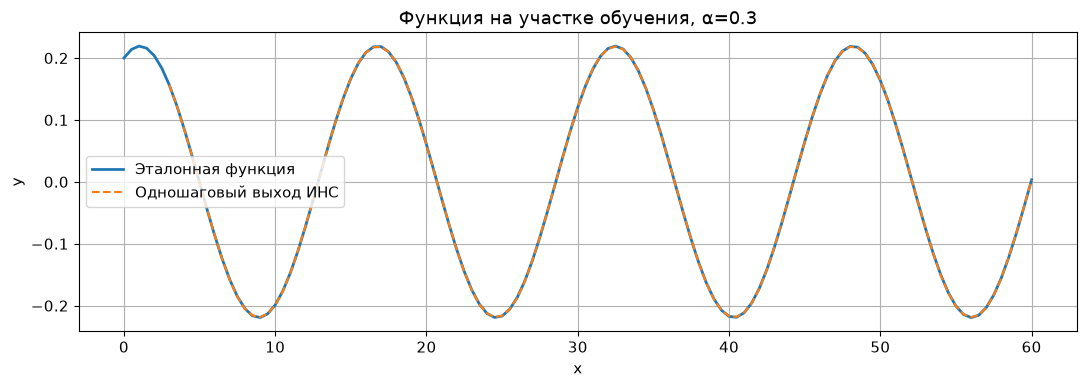

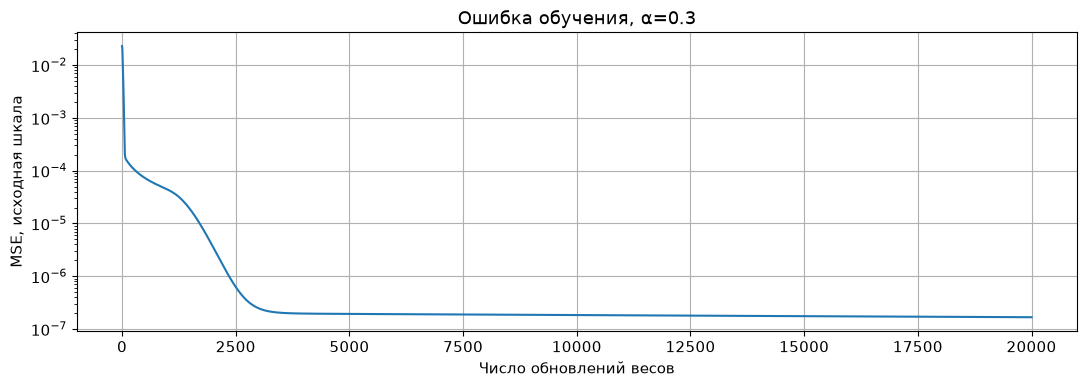

In [5]:
train_pred = predict(X, weights).ravel()*scale+mu
train_true = y[LAGS:N_TRAIN]
train_table = pd.DataFrame({"x": x[LAGS:N_TRAIN], "Эталонное значение": train_true,
                            "Полученное значение": train_pred, "Отклонение": train_pred-train_true})
display(train_table)
train_table.to_csv(OUT/"training.csv",index=False,encoding="utf-8-sig")
fig, ax = plt.subplots()
ax.plot(x[:N_TRAIN],y[:N_TRAIN], label="Эталонная функция", linewidth=2)
ax.plot(x[LAGS:N_TRAIN],train_pred,"--",label="Одношаговый выход ИНС")
ax.set(xlabel="x",ylabel="y",title=f"Функция на участке обучения, α={best_alpha}")
ax.legend(); fig.tight_layout(); fig.savefig(OUT/"03_training.png",dpi=160); plt.show()
fig, ax = plt.subplots()
ax.semilogy(np.arange(EPOCHS+1),history)
ax.set(xlabel="Число обновлений весов",ylabel="MSE, исходная шкала",title=f"Ошибка обучения, α={best_alpha}")
fig.tight_layout(); fig.savefig(OUT/"04_loss.png",dpi=160); plt.show()

## 6. Результаты прогнозирования
Прогноз теста начинается в x=80.5. К этому моменту наблюдения до x=80 считаются известными, поэтому начальное окно состоит из последних шести фактических значений валидации. Веса и нормирование остаются полученными только на обучении. Затем выполняются **40 рекурсивных шагов без подстановки истинных значений теста**. Это отдельный прогноз из более поздней точки, а не непрерывное продолжение валидационного прогноза.

Для сравнения используется прогноз сохранения последнего наблюдения: одно и то же последнее известное значение на всех 40 шагах. Эталонная формула используется для генерации ряда и оценки ошибки; модель получает только шесть лагов.

,Шаг,x,Эталонное значение,Полученное значение,Отклонение
0,1,80.50000000,0.20516382,0.20527943,0.00011561
1,2,81.00000000,0.18567534,0.18629633,0.00062099
2,3,81.50000000,0.15878457,0.15978781,0.00100325
3,4,82.00000000,0.12556355,0.12661583,0.00105228
4,5,82.50000000,0.08733672,0.08812937,0.00079265
5,6,83.00000000,0.04562804,0.04620917,0.00058113
6,7,83.50000000,0.00210032,0.00279630,0.00069598
7,8,84.00000000,-0.04151113,-0.04043277,0.00107836
8,9,84.50000000,-0.08346767,-0.08212911,0.00133856
9,10,85.00000000,-0.12209661,-0.12097090,0.00112572


,MSE,RMSE,MAE,MaxAE
Обучение: один шаг,0.00000017,0.00040921,0.00036757,0.00062420
Валидация: 40 шагов,0.00000028,0.00053325,0.00043820,0.00117953
Тест: 40 шагов,0.00000056,0.00075159,0.00063795,0.00146448
Тест: последнее значение,0.06120870,0.24740392,0.19851991,0.43574795


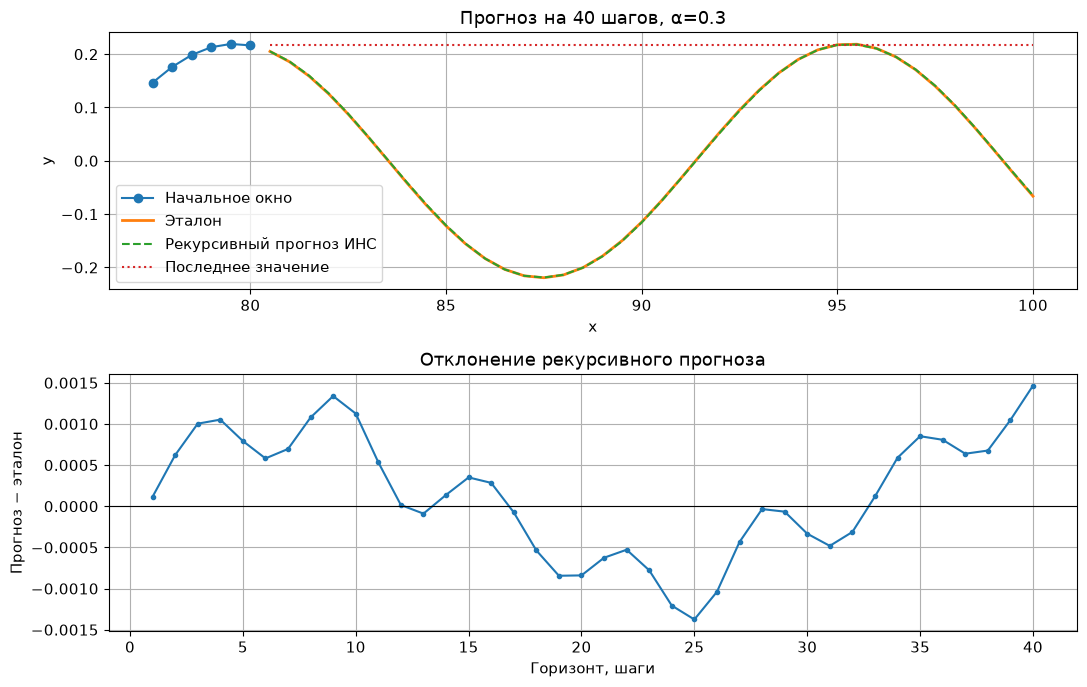

In [6]:
test_start = N_TRAIN+N_VAL
test_pred = recursive(z[test_start-LAGS:test_start], len(y)-test_start, weights)
test_true = y[test_start:]
test_table = pd.DataFrame({"Шаг": np.arange(1,len(test_true)+1), "x": x[test_start:],
                           "Эталонное значение": test_true, "Полученное значение": test_pred,
                           "Отклонение": test_pred-test_true})
display(test_table)
test_table.to_csv(OUT/"forecast.csv",index=False,encoding="utf-8-sig")
baseline = np.full_like(test_true,y[test_start-1])
train_scores = metrics(train_true,train_pred)
val_scores = metrics(y[N_TRAIN:test_start],best["validation"])
test_scores = metrics(test_true,test_pred)
baseline_scores = metrics(test_true,baseline)
score_table = pd.DataFrame([train_scores,val_scores,test_scores,baseline_scores],
    index=["Обучение: один шаг","Валидация: 40 шагов","Тест: 40 шагов","Тест: последнее значение"])
display(score_table)
score_table.to_csv(OUT/"metrics.csv",encoding="utf-8-sig")
fig, axes = plt.subplots(2,1,figsize=(11,7))
axes[0].plot(x[test_start-LAGS:test_start],y[test_start-LAGS:test_start],"o-",label="Начальное окно")
axes[0].plot(x[test_start:],test_true,label="Эталон",linewidth=2)
axes[0].plot(x[test_start:],test_pred,"--",label="Рекурсивный прогноз ИНС")
axes[0].plot(x[test_start:],baseline,":",label="Последнее значение")
axes[0].set(xlabel="x",ylabel="y",title=f"Прогноз на 40 шагов, α={best_alpha}")
axes[0].legend()
axes[1].plot(np.arange(1,len(test_true)+1),test_pred-test_true,"o-",markersize=3)
axes[1].axhline(0,color="black",linewidth=0.8)
axes[1].set(xlabel="Горизонт, шаги",ylabel="Прогноз − эталон",title="Отклонение рекурсивного прогноза")
fig.tight_layout(); fig.savefig(OUT/"05_forecast.png",dpi=160); plt.show()

# Контроль целостности расчёта: форма сети и хронология выборок.
assert [w.shape for w in weights] == [(6,2),(1,2),(2,1),(1,1)]
assert len(train_table)==115 and len(test_table)==40
assert x[N_TRAIN-1] < x[N_TRAIN] < x[test_start] and np.isfinite(test_pred).all()

## 7. Выводы
Следующая ячейка формирует выводы по фактическим результатам текущего запуска.

In [7]:
improvement = baseline_scores["RMSE"]/test_scores["RMSE"]
display(Markdown(f"""
1. Построена нелинейная прогнозирующая ИНС **6–2–1** с 17 параметрами, сигмоидой в скрытом слое и линейным выходом. Она обучена методом обратного распространения ошибки и полного градиентного спуска.
2. Из проверенных шагов обучения минимальную ошибку 40-шагового валидационного прогноза дал **α={best_alpha:g}**: MSE = **{val_scores['MSE']:.8g}**, RMSE = **{val_scores['RMSE']:.8g}**. Малый шаг замедляет сходимость, а самый большой проверенный шаг даёт худшее качество; рост α не гарантирует улучшения.
3. После {EPOCHS:,} обновлений MSE обучения = **{train_scores['MSE']:.8g}**, RMSE = **{train_scores['RMSE']:.8g}**. Сеть воспроизводит периодический обучающий ряд.
4. На независимом тесте из 40 рекурсивных шагов MSE = **{test_scores['MSE']:.8g}**, RMSE = **{test_scores['RMSE']:.8g}**, MAE = **{test_scores['MAE']:.8g}**, максимальное абсолютное отклонение = **{test_scores['MaxAE']:.8g}**. RMSE прогноза сохранения последнего наблюдения = **{baseline_scores['RMSE']:.8g}**; у ИНС она меньше примерно в **{improvement:.1f} раза**.
5. При рекурсивном прогнозировании ошибки предыдущих шагов входят в новые входные окна. Ошибка может накапливаться и колебаться, поэтому малая ошибка одношагового восстановления сама по себе не гарантирует точного длинного прогноза.
6. Выводы относятся к выбранной сетке и чистому детерминированному ряду. При b=d исходная функция представляет одну гармонику; успешность на этом примере не доказывает такое же качество на шумных или непериодических данных. Минимальность ошибки установлена только среди пяти проверенных α при одном seed и фиксированном числе эпох.
"""))


1. Построена нелинейная прогнозирующая ИНС **6–2–1** с 17 параметрами, сигмоидой в скрытом слое и линейным выходом. Она обучена методом обратного распространения ошибки и полного градиентного спуска.
2. Из проверенных шагов обучения минимальную ошибку 40-шагового валидационного прогноза дал **α=0.3**: MSE = **2.8435503e-07**, RMSE = **0.0005332495**. Малый шаг замедляет сходимость, а самый большой проверенный шаг даёт худшее качество; рост α не гарантирует улучшения.
3. После 20,000 обновлений MSE обучения = **1.6744894e-07**, RMSE = **0.00040920526**. Сеть воспроизводит периодический обучающий ряд.
4. На независимом тесте из 40 рекурсивных шагов MSE = **5.6488727e-07**, RMSE = **0.00075158983**, MAE = **0.00063794839**, максимальное абсолютное отклонение = **0.0014644787**. RMSE прогноза сохранения последнего наблюдения = **0.24740392**; у ИНС она меньше примерно в **329.2 раза**.
5. При рекурсивном прогнозировании ошибки предыдущих шагов входят в новые входные окна. Ошибка может накапливаться и колебаться, поэтому малая ошибка одношагового восстановления сама по себе не гарантирует точного длинного прогноза.
6. Выводы относятся к выбранной сетке и чистому детерминированному ряду. При b=d исходная функция представляет одну гармонику; успешность на этом примере не доказывает такое же качество на шумных или непериодических данных. Минимальность ошибки установлена только среди пяти проверенных α при одном seed и фиксированном числе эпох.


## 8. Ответы на контрольные вопросы

**1. ИНС какой архитектуры использована? Принцип построения.**  
Многослойный персептрон прямого распространения 6–2–1: шесть входов соответствуют лагам ряда, два скрытых нейрона вычисляют сигмоиды взвешенных сумм, выходной нейрон линейно объединяет их результаты. Полносвязные слои имеют смещения. Обратных связей внутри сети нет; рекурсия организуется внешним алгоритмом прогноза.

**2. Как функционирует сеть?**  
Последние шесть наблюдений нормируются по параметрам обучения и поступают на вход. Скрытый слой формирует два нелинейных признака, выходной слой выдаёт оценку следующего нормированного значения. Обратное преобразование $\hat y=s\hat z+\mu$ возвращает результат в исходный масштаб.

**3. Алгоритм обучения.**  
Инициализировать веса, сформировать окна, выполнить прямой проход, вычислить MSE, распространить её производные от выхода к скрытому слою и обновить все веса и смещения по правилу градиентного спуска. Повторить 20 000 раз. Для разных $\alpha$ использовать одинаковую инициализацию, затем выбрать модель по валидации.

**4. Как формируется обучающая выборка?**  
Ряд дискретизируется с постоянным шагом. Скользящее окно из шести последовательных значений образует признаки, следующее значение — цель. Из 121 значения получается $121-6=115$ пар. Хронологический порядок сохраняется; параметры нормирования не используют будущее.

**5. Как выполняется многошаговый прогноз?**  
Получить прогноз из последнего известного окна, удалить самое старое значение, добавить полученный прогноз и повторить. После первого шага в окне постепенно появляются собственные прогнозы модели. Истинные будущие значения при таком прогнозе не подставляются.

**6. Критерии качества прогноза.**  
Для $e_k=\hat y_k-y_k$:
$$\mathrm{MSE}=\frac1n\sum e_k^2,\quad \mathrm{RMSE}=\sqrt{\mathrm{MSE}},\quad
\mathrm{MAE}=\frac1n\sum|e_k|,\quad \mathrm{MaxAE}=\max|e_k|.$$
RMSE и MAE имеют размерность исходного ряда. Дополнительно следует сравнивать ошибку с простым базовым прогнозом и исследовать зависимость отклонений от горизонта. MAPE для этого ряда неудобна, поскольку значения проходят через ноль.

## 9. Сохранение результатов
При запуске создаётся папка `lab5_results`: полные таблицы CSV, графики PNG и параметры сети. Последняя ячейка формирует архив; в Colab его можно скачать через панель «Файлы».

**Источник задания:** предоставленный файл «Лабораторная работа 5.pdf», страницы 1–2. Личные данные титульного листа не были предоставлены и заполняются перед сдачей.

In [8]:
import shutil
np.savez(OUT/"model.npz",W1=weights[0],b1=weights[1],W2=weights[2],b2=weights[3],
         mean=mu,scale=scale,alpha=best_alpha,lags=LAGS,dx=DX,seed=SEED)
archive = shutil.make_archive("lab5_variant10_results","zip",OUT)
print("Готово. Архив результатов:",archive)

Готово. Архив результатов: C:\Users\Admin\Documents\Codex\2026-11-22\new-chat\work\lab5_variant10_results.zip
